# 03 · Exploratory data analysis and baselines (Module 5)

Questions:

1. Do the four regions really have different seasonal solar regimes?
2. Is the forecast archive complete enough?
3. How does the raw ECMWF forecast relate to the NASA target, and does its error differ by region, season and lead time?
4. How good are the two reference baselines: the raw forecast and the climatology?

**Leakage rule:** relationships between forecasts and the target (sections 3–4) are explored on the **training split only**. The long-term NASA climatology (2001–2023) predates all splits. Baselines have no fitted parameters, so they are reported on validation and test as reference scores for Module 6.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.3f}".format)
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from src.viz import set_style, REGION_ORDER, REGION_LABEL, REGION_COLOR, NEUTRAL, INK_2, label_line_ends
from src.preprocessing.build_training_data import load_config, TARGET, SPLITS
from src.models.evaluate import evaluation_table, grouped_metrics

set_style()
cfg = load_config()
PROCESSED = ROOT / "data" / "processed"
FIG = ROOT / "results" / "eda"; FIG.mkdir(parents=True, exist_ok=True)
BASE = ROOT / "results" / "baselines"; BASE.mkdir(parents=True, exist_ok=True)

nasa = pd.read_csv(PROCESSED / "nasa_solar_history.csv", parse_dates=["date"])
fc_raw = pd.read_csv(PROCESSED / "archived_forecasts.csv", parse_dates=["target_date"])
data = pd.read_csv(PROCESSED / "solar_model_training.csv", parse_dates=["target_date"])
train = data[data["split"] == "train"]
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
print(data["split"].value_counts().loc[list(SPLITS)])

split
train         5060
validation    2208
test          4296
Name: count, dtype: int64


## 1. Long-term seasonal cycle by region (NASA POWER, 2001–2023)

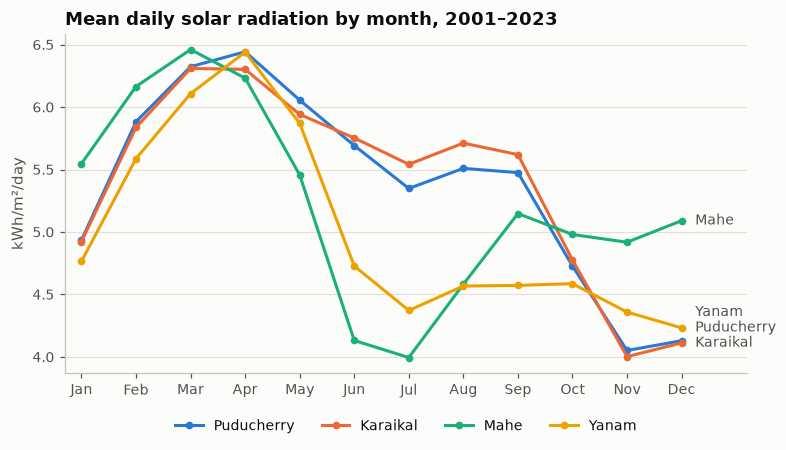

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
region_id,,,,,,,,,,,,
Puducherry,4.935,5.883,6.323,6.443,6.056,5.692,5.349,5.509,5.475,4.727,4.051,4.129
Karaikal,4.923,5.837,6.310,6.302,5.941,5.753,5.542,5.712,5.620,4.776,4.002,4.112
Mahe,5.547,6.164,6.461,6.232,5.457,4.131,3.995,4.582,5.147,4.980,4.918,5.090
Yanam,4.765,5.587,6.107,6.440,5.870,4.728,4.372,4.567,4.572,4.586,4.359,4.232


In [2]:
hist = nasa[nasa["date"].dt.year <= 2023].assign(month=lambda d: d["date"].dt.month)
monthly = hist.groupby(["month", "region_id"])["ALLSKY_SFC_SW_DWN"].mean().unstack()[REGION_ORDER]

fig, ax = plt.subplots(figsize=(8, 4))
for r in REGION_ORDER:
    ax.plot(monthly.index, monthly[r], color=REGION_COLOR[r], label=REGION_LABEL[r], marker="o")
label_line_ends(ax, monthly.iloc[-1].to_dict(), 12)
ax.set_xticks(range(1, 13), MONTHS); ax.set_xlim(0.7, 13.2)
ax.set_ylabel("kWh/m²/day"); ax.set_title("Mean daily solar radiation by month, 2001–2023")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.savefig(FIG / "seasonal_cycle_by_region.png"); plt.show()
monthly.rename(columns=REGION_LABEL).T.set_axis(MONTHS, axis=1)

In [3]:
# year-to-year variability of each month's mean (std across years)
yr = hist.assign(year=hist["date"].dt.year).groupby(["region_id", "year", "month"])["ALLSKY_SFC_SW_DWN"].mean()
yr.groupby(["region_id", "month"]).std().unstack().loc[REGION_ORDER].set_axis(MONTHS, axis=1).rename(index=REGION_LABEL)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
region_id,,,,,,,,,,,,
Puducherry,0.294,0.229,0.321,0.257,0.338,0.289,0.300,0.281,0.325,0.274,0.500,0.397
Karaikal,0.309,0.250,0.305,0.265,0.315,0.226,0.273,0.335,0.310,0.318,0.450,0.362
Mahe,0.199,0.198,0.215,0.260,0.521,0.370,0.427,0.459,0.524,0.303,0.347,0.241
Yanam,0.187,0.198,0.247,0.207,0.181,0.393,0.479,0.408,0.324,0.447,0.420,0.261


**Observations**

- **The regions have different regimes, which confirms the regionality concern.**
  - Puducherry and Karaikal stay above 5.3 kWh/m²/day through the south-west monsoon. Their low point is in **November–December**, at about 4.0, during the north-east monsoon.
  - Mahe drops sharply in **June–July**, to about 4.0, during the south-west monsoon, but stays at about 5.0 from October to December.
  - Yanam is low for a long stretch, at about 4.2–4.7 from **June to December**: the south-west monsoon plus the post-monsoon and cyclone season.
- **The largest gap between regions is about 1.6 kWh/m²/day,** in July: Karaikal 5.5 vs Mahe 4.0. In December the order flips: Mahe is about 1 kWh/m²/day *above* Puducherry and Karaikal.
- **Year-to-year variability (standard deviation) is highest in each region's monsoon months.** It is about 0.5 in Puducherry and Karaikal in November, and in Mahe from May to September. Those months will be the hardest to predict and will dominate the errors.

## 2. Correlation between regions' daily NASA values
If two regions were effectively the same signal, a region-aware model would gain little from treating them separately.

In [4]:
w = nasa[nasa["date"].dt.year <= 2023].pivot(index="date", columns="region_id", values="ALLSKY_SFC_SW_DWN")[REGION_ORDER]
anom = w - w.groupby(w.index.day_of_year).transform("mean")   # remove the shared seasonal cycle
pd.concat({"raw daily": w.corr(), "daily anomaly (seasonal cycle removed)": anom.corr()}, axis=1).rename(index=REGION_LABEL)

raw daily                      daily anomaly (seasonal cycle removed)                     
region_id  puducherry karaikal  mahe yanam                             puducherry karaikal  mahe yanam
region_id                                                                                             
Puducherry      1.000    0.906 0.399 0.453                                  1.000    0.852 0.374 0.275
Karaikal        0.906    1.000 0.340 0.367                                  0.852    1.000 0.335 0.182
Mahe            0.399    0.340 1.000 0.397                                  0.374    0.335 1.000 0.211
Yanam           0.453    0.367 0.397 1.000                                  0.275    0.182 0.211 1.000

**Observations**

- Puducherry and Karaikal are about 110 km apart, and they are strongly correlated even after the seasonal cycle is removed (r = 0.85).
- Mahe and Yanam are only weakly correlated with each other and with the eastern regions (anomaly r = 0.18–0.37).
- So in practice there are **three climate regimes**: the Coromandel coast (Puducherry and Karaikal), the Malabar coast (Mahe) and the Godavari delta (Yanam).
- A region-aware model should mainly need to learn the differences for Mahe and Yanam.

## 3. Forecast archive coverage
Share of (target date × lead) rows that are complete, per month. The dropped rows are listed in `results/preprocessing/data_quality.json`.

In [5]:
cov = fc_raw.assign(month=fc_raw["target_date"].dt.to_period("M"), ok=fc_raw["hours_complete"] == 24)
cov = cov.groupby(["month", "region_id"])["ok"].mean().unstack()[REGION_ORDER]
cov[cov.min(axis=1) < 1].rename(columns=REGION_LABEL)

region_id,Puducherry,Karaikal,Mahe,Yanam
month,,,,
2024-03,0.789,0.789,0.789,0.789
2026-04,0.767,0.767,0.767,0.767


**Observations**

Only two months are incomplete:

- **March 2024:** the ECMWF archive starts on about 9 March.
- **April 2026:** a 6-day archive outage, 17–22 April. The shift to IST days spills it into 23 April.

Every region is affected identically, and these days are dropped rather than imputed.

## 4. Raw ECMWF forecast vs NASA target (training split)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


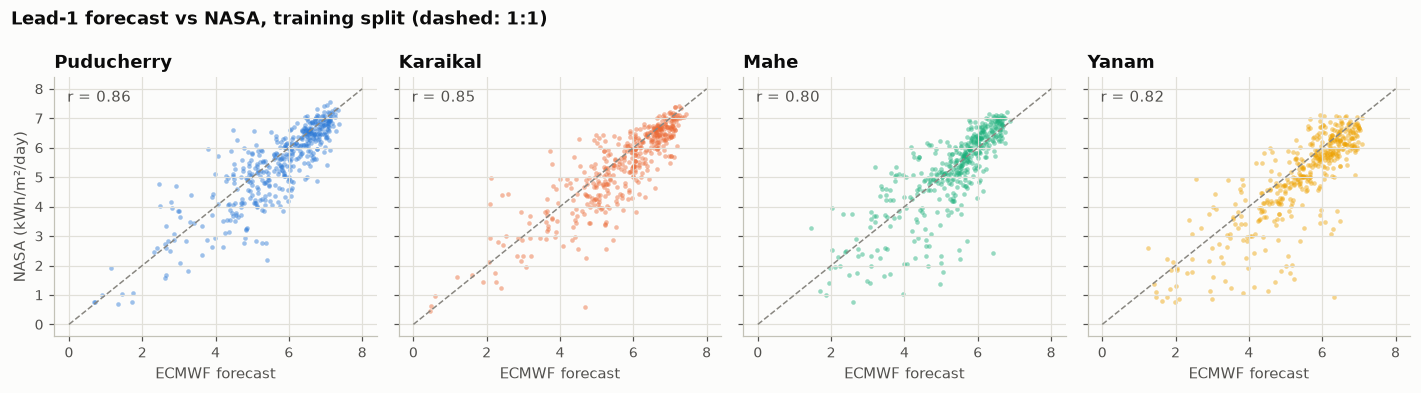

In [6]:
lead1 = train[train["lead_days"] == 1]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharex=True, sharey=True)
for ax, r in zip(axes, REGION_ORDER):
    g = lead1[lead1["region_id"] == r]
    ax.scatter(g["forecast_shortwave_radiation"], g[TARGET], s=9, alpha=0.45, color=REGION_COLOR[r], linewidths=0)
    ax.plot([0, 8], [0, 8], color=NEUTRAL, lw=1, ls="--")
    ax.set_title(REGION_LABEL[r]); ax.set_xlabel("ECMWF forecast"); ax.grid(axis="x")
    ax.text(0.04, 0.95, f"r = {g['forecast_shortwave_radiation'].corr(g[TARGET]):.2f}", transform=ax.transAxes, va="top", color=INK_2)
axes[0].set_ylabel("NASA (kWh/m²/day)")
fig.suptitle("Lead-1 forecast vs NASA, training split (dashed: 1:1)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); fig.savefig(FIG / "forecast_vs_nasa_lead1.png"); plt.show()

### 4a. Forecast error by month and region
Error = forecast − NASA. If the bias pattern differs by region and season, a correction model needs region and season information.

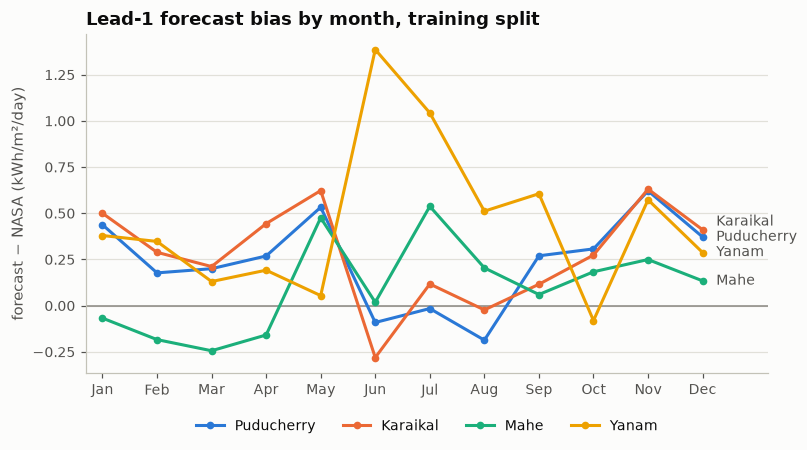

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
region_id,,,,,,,,,,,,
Puducherry,0.438,0.178,0.200,0.269,0.533,-0.091,-0.015,-0.187,0.270,0.307,0.622,0.372
Karaikal,0.500,0.289,0.212,0.444,0.623,-0.281,0.117,-0.023,0.116,0.274,0.631,0.411
Mahe,-0.067,-0.184,-0.244,-0.158,0.476,0.019,0.538,0.205,0.060,0.184,0.250,0.134
Yanam,0.380,0.348,0.131,0.192,0.055,1.386,1.043,0.512,0.606,-0.080,0.573,0.288


In [7]:
err = train.assign(error=train["forecast_shortwave_radiation"] - train[TARGET], month=train["target_date"].dt.month)
bias = err[err["lead_days"] == 1].groupby(["month", "region_id"])["error"].mean().unstack()[REGION_ORDER]

fig, ax = plt.subplots(figsize=(8, 4))
ax.axhline(0, color=NEUTRAL, lw=1)
for r in REGION_ORDER:
    ax.plot(bias.index, bias[r], color=REGION_COLOR[r], label=REGION_LABEL[r], marker="o")
label_line_ends(ax, bias.iloc[-1].to_dict(), 12)
ax.set_xticks(range(1, 13), MONTHS); ax.set_xlim(0.7, 13.2)
ax.set_ylabel("forecast − NASA (kWh/m²/day)"); ax.set_title("Lead-1 forecast bias by month, training split")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.savefig(FIG / "forecast_bias_by_month.png"); plt.show()
bias.rename(columns=REGION_LABEL).T.set_axis(MONTHS, axis=1)

**Observations**

- **ECMWF over-forecasts in most months** (positive bias), by +0.26 kWh/m²/day across the training split.
- **The bias pattern is specific to region and season:**
  - **Yanam** is over-forecast by **+1.0 to +1.4** in June–July, during the south-west monsoon. ECMWF misses much of the monsoon cloud there.
  - **Mahe** is *under*-forecast from January to April (about −0.2). It is the only region with negative bias in the dry season.
  - **Puducherry and Karaikal** are over-forecast most in **May** and **November** (about +0.5 to +0.6). November is the north-east monsoon onset.
- This is the strongest argument for the region-aware model with seasonal features (§7.6): a single global bias correction would fix none of these patterns.
- **Caveat:** the training split covers each calendar month only once (March–May twice), so these monthly bias estimates come from a single year and are noisy.

### 4b. Error by lead time

In [8]:
lead_tbl = grouped_metrics(err, TARGET, "forecast_shortwave_radiation", ["region_id", "lead_days"])
lead_tbl.pivot(index="region_id", columns="lead_days", values="mae").loc[REGION_ORDER].rename(index=REGION_LABEL).add_prefix("MAE lead ")

lead_days,MAE lead 1,MAE lead 2,MAE lead 3
region_id,,,
Puducherry,0.555,0.558,0.598
Karaikal,0.560,0.591,0.632
Mahe,0.588,0.633,0.677
Yanam,0.674,0.701,0.752


### 4c. Which forecast variables relate to the target and to the forecast error? (training split, Pearson r)

In [9]:
cols = ["forecast_shortwave_radiation", "forecast_cloud_cover_mean", "forecast_humidity_mean",
        "forecast_precipitation_sum", "forecast_temperature_mean", "forecast_temperature_max",
        "forecast_temperature_min", "forecast_wind_speed_mean", "climatology_solar_radiation", "clear_sky_radiation"]
corr = pd.DataFrame({"with NASA target": train[cols].corrwith(train[TARGET]),
                     "with residual (NASA − forecast)": train[cols].corrwith(train["target_residual"])})
corr.sort_values("with NASA target", key=abs, ascending=False)

,with NASA target,with residual (NASA − forecast)
forecast_shortwave_radiation,0.806,-0.132
climatology_solar_radiation,0.687,0.151
forecast_cloud_cover_mean,-0.684,0.009
forecast_temperature_max,0.524,-0.081
forecast_precipitation_sum,-0.504,0.036
forecast_humidity_mean,-0.451,0.029
clear_sky_radiation,0.431,0.037
forecast_temperature_mean,0.425,-0.054
forecast_wind_speed_mean,-0.253,-0.131
forecast_temperature_min,0.140,-0.021


**Observations**

- **Forecast shortwave radiation is by far the strongest predictor** (r = 0.81), followed by cloud cover (−0.68) and climatology (0.69).
- **Linear correlation with the residual is weak** for every variable (|r| ≤ 0.15). The forecast error is not explained by any single variable on its own, so a linear correction will gain little.
- Any improvement will have to come from **interactions**, such as region × season × cloud cover, which suits tree models (Random Forest, XGBoost).
- The weak negative correlation between forecast shortwave and the residual (−0.13) shows that the forecast is most over-confident on days it predicts to be sunny.

## 5. Baselines

Neither baseline has any parameters fitted on the 2024+ data, so both can be scored on every split:

- **Raw forecast:** ECMWF daily shortwave radiation (kWh/m²/day).
- **Climatology:** the smoothed day-of-year mean of NASA for each region, 2001–2023.

Module 6 models must beat these on **validation** (for model selection) and on **test** (for the final claim).

In [10]:
preds = {"raw_forecast": "forecast_shortwave_radiation", "climatology": "climatology_solar_radiation"}
baseline = evaluation_table(data, TARGET, preds)
baseline.to_csv(BASE / "baseline_metrics.csv", index=False)
ov = baseline[baseline["scope"] == "overall"].pivot(index="model", columns="split", values=["mae", "rmse", "r2"])
ov.reindex(columns=list(SPLITS), level=1)

mae                   rmse                     r2                 
split        train validation  test train validation  test train validation  test
model                                                                            
climatology  0.770      1.038 0.773 1.070      1.336 1.064 0.442      0.127 0.356
raw_forecast 0.627      0.785 0.711 0.895      1.061 0.990 0.610      0.450 0.442

In [11]:
# per region and per lead, validation and test
for scope in ("region", "lead"):
    t = baseline[(baseline["scope"] == scope) & baseline["split"].isin(["validation", "test"])]
    display(t.pivot_table(index=["split", "group"], columns="model", values=["mae", "rmse"]).loc[["validation", "test"]])

mae                     rmse             
model                 climatology raw_forecast climatology raw_forecast
split      group                                                       
validation karaikal         0.836        0.679       1.111        0.933
           mahe             1.076        0.820       1.377        1.064
           puducherry       0.911        0.770       1.177        1.033
           yanam            1.328        0.872       1.620        1.196
test       karaikal         0.815        0.684       1.114        0.943
           mahe             0.690        0.646       0.916        0.922
           puducherry       0.753        0.680       1.065        0.909
           yanam            0.835        0.835       1.147        1.166

mae                     rmse             
model            climatology raw_forecast climatology raw_forecast
split      group                                                  
validation 1           1.038        0.721       1.336        0.983
           2           1.038        0.780       1.336        1.059
           3           1.038        0.854       1.336        1.135
test       1           0.773        0.651       1.064        0.894
           2           0.773        0.729       1.064        1.016
           3           0.773        0.754       1.064        1.054

In [12]:
summary = {s: {m: baseline.query("scope=='overall' and split==@s and model==@m")[["mae", "rmse", "r2", "bias"]].iloc[0].round(4).to_dict()
                for m in preds} for s in SPLITS}
(BASE / "baseline_metrics.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
summary

{'train': {'raw_forecast': {'mae': 0.6266,
   'rmse': 0.8945,
   'r2': 0.6102,
   'bias': 0.2634},
  'climatology': {'mae': 0.7698,
   'rmse': 1.0705,
   'r2': 0.4418,
   'bias': 0.1663}},
 'validation': {'raw_forecast': {'mae': 0.785,
   'rmse': 1.0608,
   'r2': 0.4498,
   'bias': 0.3238},
  'climatology': {'mae': 1.0381,
   'rmse': 1.3362,
   'r2': 0.1269,
   'bias': 0.2903}},
 'test': {'raw_forecast': {'mae': 0.7112,
   'rmse': 0.9903,
   'r2': 0.4422,
   'bias': 0.4509},
  'climatology': {'mae': 0.7734, 'rmse': 1.0641, 'r2': 0.356, 'bias': 0.0821}}}

## Summary and implications for Module 6

| Baseline | Validation MAE | Test MAE | Test R² |
|---|---|---|---|
| Raw ECMWF forecast | **0.785** | **0.711** | 0.44 |
| Climatology (2001–2023) | 1.038 | 0.773 | 0.36 |

1. **The raw forecast is the baseline to beat.** It beats climatology overall, for every lead and on validation for every region. On test, though, it only ties climatology for Yanam (MAE 0.835 for both) and loses to it slightly on RMSE for Mahe and Yanam.
2. **Accuracy drops with lead time.** At lead 3 on test, the raw forecast (MAE 0.754) is only slightly better than climatology (0.773). There is room for the model to blend the two.
3. **The bias grows over time:** +0.26 on train, +0.32 on validation, +0.45 on test. The raw forecast is getting *more* over-confident. Possible causes are ECMWF model upgrades or changes in the NASA data. This is a **non-stationarity risk**: a correction learned on 2024 data may under-correct in 2026. Module 6 should check the bias on test and consider retraining on train + validation before the final test.
4. **Validation (May–Nov 2025) is harder than test.** It is dominated by the south-west monsoon, so scores on the two splits are not directly comparable. Compare models against the baseline *within* the same split.
5. **Regionality is real.** The seasonal cycles and forecast-bias patterns differ by region, so Module 6 should use the region-aware model and run the ablation in §10.4.

Saved outputs: figures in `results/eda/`, and baseline metrics in `results/baselines/baseline_metrics.csv` and `.json`.